# Caso A — PC2: modelado y recomendación
**Business Analytics (AD3010) · UTEC · Ciclo 2026-2 · Equipo 6**

Cliente: distribuidora musical latinoamericana que evalúa entrar al mercado peruano.
Decisión: **a qué artistas y géneros fichar.**

---

## Qué hace este notebook

| Sección | Contenido | Rúbrica PC2 |
|---|---|---|
| 1 | Carga de las tres fuentes | — |
| 2 | **Etiquetado de géneros** — cierra el pendiente de PC1 | criterio 1 |
| 3 | Tabla analítica: una fila por canción | — |
| 4 | **Modelo 1 — Regresión logística** (H3) | criterio 1 |
| 5 | **Modelo 2 — Serie de tiempo** (H4) | criterio 1 |
| 6 | **Modelo 3 — Clustering** (H1) | criterio 1 |
| 7 | **Pregunta huérfana** respondida | criterio 2 |
| 8 | **Recomendación**: lista de fichaje | criterio 3 |
| 9 | Exports para el dashboard de Power BI | criterio 4 |
| 10 | Checklist contra la rúbrica | — |

## Cómo correrlo

Necesita tres archivos:
1. Los dos datasets de Kaggle (se descargan solos con `kagglehub`).
2. `encuesta_habitos_limpia.csv`, el CSV que produjo el notebook de PC1.




## 0. Setup


In [1]:
!pip install -q kagglehub statsmodels scikit-learn

import re, unicodedata, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 11})

PLUM, AMBAR, CARMIN, GRIS = "#2D1B41", "#E09F3E", "#C1121F", "#8D99AE"
PAIS = "PE"
REGION = ["MX", "CO", "CL", "AR"]
AUDIO = ["danceability", "energy", "loudness", "speechiness", "acousticness",
         "instrumentalness", "liveness", "valence", "tempo"]
SEMILLA = 42          # toda aleatoriedad del notebook sale de acá

def banner(t):
    print()
    print("=" * 74)
    print(t)
    print("=" * 74)

print("listo")


listo


---
# 1. Carga de las tres fuentes


In [2]:
import kagglehub
p_cat = kagglehub.dataset_download("maharshipandya/-spotify-tracks-dataset")
p_chart = kagglehub.dataset_download("asaniczka/top-spotify-songs-in-73-countries-daily-updated")
print(p_cat)
print(p_chart)


Using Colab cache for faster access to the '-spotify-tracks-dataset' dataset.


100%|██████████| 162M/162M [00:03<00:00, 56.2MB/s]

Extracting files...


/kaggle/input/-spotify-tracks-dataset
/root/.cache/kagglehub/datasets/asaniczka/top-spotify-songs-in-73-countries-daily-updated/versions/608


In [3]:
def resolver_csv(ruta, pista=""):
    """Acepta un .csv o la carpeta que devuelve kagglehub."""
    p = Path(ruta)
    if p.is_file():
        return str(p)
    cand = sorted(p.rglob("*.csv"), key=lambda f: f.stat().st_size, reverse=True)
    if not cand:
        raise SystemExit(f"No hay .csv en {ruta}")
    con = [f for f in cand if pista.lower() in f.name.lower()] if pista else []
    elegido = (con or cand)[0]
    print(f"  {elegido.name} ({elegido.stat().st_size/1e6:.0f} MB)")
    return str(elegido)

# --- catálogo
r = resolver_csv(p_cat, "track")
cab = pd.read_csv(r, nrows=0).columns
cat = pd.read_csv(r, index_col=0) if str(cab[0]).startswith("Unnamed") else pd.read_csv(r)

# --- panel, por partes para no agotar la RAM de Colab
r = resolver_csv(p_chart, "universal")
trozos, total = [], 0
for chunk in pd.read_csv(r, chunksize=400_000, low_memory=False):
    total += len(chunk)
    trozos.append(chunk[chunk["country"].isin([PAIS, *REGION])])
panel = pd.concat(trozos, ignore_index=True)
panel["snapshot_date"] = pd.to_datetime(panel["snapshot_date"])
pe = panel[panel["country"] == PAIS].copy()

banner("CARGA")
print(f"  Catálogo:       {len(cat):,} filas · {cat['track_id'].nunique():,} canciones únicas")
print(f"  Panel completo: {total:,} filas leídas")
print(f"  Panel filtrado: {len(panel):,} filas (5 países)")
print(f"  Perú:           {len(pe):,} filas · {pe['spotify_id'].nunique()} canciones")
print(f"  Ventana:        {pe['snapshot_date'].min().date()} a {pe['snapshot_date'].max().date()}")


  dataset.csv (20 MB)
  universal_top_spotify_songs.csv (498 MB)

CARGA
  Catálogo:       114,000 filas · 89,741 canciones únicas
  Panel completo: 2,110,316 filas leídas
  Panel filtrado: 145,337 filas (5 países)
  Perú:           29,056 filas · 441 canciones
  Ventana:        2023-10-18 a 2025-06-11


### 1.1 Encuesta

Sube `encuesta_habitos_limpia.csv`, el archivo que exportó el notebook de PC1.


In [4]:
from google.colab import files
subidos = files.upload()

# Detectar si el archivo es CSV o Excel (.xlsx)
RUTA_ENCUESTA = [k for k in subidos if k.endswith(".csv") or k.endswith(".xlsx")][0]

if RUTA_ENCUESTA.endswith(".xlsx"):
    encuesta = pd.read_excel(RUTA_ENCUESTA)
else:
    encuesta = pd.read_csv(RUTA_ENCUESTA)

print("encuesta:", encuesta.shape)
print([c for c in encuesta.columns][:8], "...")

Saving encuesta_limpia-3.csv to encuesta_limpia-3.csv
encuesta: (67, 28)
['Marca temporal', '¿Aceptas participar?', 'rango_edad', 'plataforma', 'tipo_cuenta', 'dias_escucha_7d', '5. En los últimos 7 días, ¿con qué frecuencia escuchaste cada uno de estos géneros? [Reggaetón y urbano latino]', '5. En los últimos 7 días, ¿con qué frecuencia escuchaste cada uno de estos géneros? [Pop latino]'] ...


---
# 2. Etiquetado de géneros

**Este era el pendiente de PC1 y es bloqueante.** Sin género asignado no se puede
responder la pregunta huérfana ni meter el enriquecimiento al modelo.

El género se asigna por tres vías, en orden de confianza:

| Vía | Qué es | Confianza |
|---|---|---|
| **manual** | Lista curada por el equipo: artistas peruanos y artistas que emergieron después del snapshot del catálogo | alta |
| **catálogo** | Género dominante del artista en el dataset base — **esta es la vía del enriquecimiento** | media |
| **sin género** | No se pudo asignar. La fila se conserva, solo se excluye de los análisis por género | — |

La lista manual resuelve justamente lo que el catálogo global no tiene: cumbia,
criolla y el repertorio urbano reciente.


In [5]:
_FEAT = re.compile(r"\b(feat|ft|featuring|con|with|vs|x)\b\.?", flags=re.IGNORECASE)
_PUNCT = re.compile(r"[^\w\s]", flags=re.UNICODE)

def norm(t):
    """Forma canónica: minúsculas, sin tildes, sin puntuación, sin 'feat'."""
    if pd.isna(t):
        return ""
    s = unicodedata.normalize("NFKD", str(t).strip().lower())
    s = "".join(ch for ch in s if not unicodedata.combining(ch))
    return re.sub(r"\s+", " ", _PUNCT.sub(" ", _FEAT.sub(" ", s))).strip()

def explotar(df, col):
    """Una fila por (canción, artista)."""
    out = df.copy()
    out["_x"] = out[col].fillna("").astype(str).str.split(r";|,|&|/", regex=True)
    out = out.explode("_x")
    out["artista_norm"] = out["_x"].map(norm)
    return out[out["artista_norm"] != ""].drop(columns="_x")

print(norm("Los Mirlos feat. Bareto"), "|", norm("Maná"))


los mirlos bareto | mana


### 2.1 La lista manual

Construida revisando los artistas con más presencia en el Top 50 Perú que no
cruzaban con el catálogo. **Ampliar esta lista es la forma de subir la cobertura.**


In [6]:
GENERO_MANUAL = {
    "cumbia": [
        "La Única Tropical", "Grupo 5", "Agua Marina", "Armonía 10",
        "Corazón Serrano", "Hermanos Yaipén", "Los Mirlos", "Grupo Néctar",
        "Son del Duke", "Kate Candela", "Deyvis Orosco", "Explosión de Iquitos",
        "Ke Personajes", "Grupo Frontera", "Los Ángeles Azules", "Papillon",
        "Yandar & Yostin",
    ],
    "criolla": ["Eva Ayllón", "Susana Baca", "Lucha Reyes", "Chabuca Granda",
                "Los Morochucos", "Arturo Zambo Cavero"],
    "regional_mexicano": ["Peso Pluma", "Carin Leon", "Junior H", "Natanael Cano",
                          "Fuerza Regida", "Gabito Ballesteros", "Xavi"],
    "urbano_latino": [
        "Milo j", "Kapo", "FloyyMenor", "Blessd", "Taiu", "Beéle",
        "Ovy On The Drums", "Cris Mj", "Tiago PZK", "Young Miko",
        "Omar Courtz", "De La Rose", "Jere Klein", "Gittobeatz", "Jombriel",
        "Alex Krack", "Jøtta", "Alleh", "Yorghaki", "Mawell", "Pascal",
        "ATL Jacob", "Luck Ra", "Emilia", "Bizarrap",
    ],
    "k-pop": ["Jimin", "Jung Kook", "BTS", "NewJeans", "Stray Kids", "BLACKPINK",
              "Jin", "V", "LE SSERAFIM"],
    "pop_internacional": ["iñigo quintero", "The Weeknd", "Taylor Swift",
                          "Billie Eilish", "Lady Gaga", "Bruno Mars", "Benson Boone",
                          "Hozier", "Teddy Swims", "Alex Warren"],
}

MAPA_CATALOGO = {
    "reggaeton": "urbano_latino", "latino": "urbano_latino", "latin": "urbano_latino",
    "reggae": "urbano_latino", "dancehall": "urbano_latino",
    "salsa": "salsa", "spanish": "pop_latino", "romance": "pop_latino",
    "pop": "pop_internacional", "dance": "pop_internacional",
    "indie-pop": "pop_internacional", "power-pop": "pop_internacional",
    "synth-pop": "pop_internacional", "r-n-b": "pop_internacional",
    "rock": "rock", "alt-rock": "rock", "hard-rock": "rock", "punk-rock": "rock",
    "rock-n-roll": "rock", "psych-rock": "rock",
    "hip-hop": "hip_hop", "k-pop": "k-pop", "j-pop": "k-pop",
}

print(f"artistas en la lista manual: {sum(len(v) for v in GENERO_MANUAL.values())}")
print(f"track_genre mapeados del catálogo: {len(MAPA_CATALOGO)}")


artistas en la lista manual: 74
track_genre mapeados del catálogo: 23


In [7]:
unicas = pe.drop_duplicates("spotify_id")[["spotify_id", "name", "artists"]].copy()

# --- vía 1: manual
manual = {norm(a): g for g, lista in GENERO_MANUAL.items() for a in lista}
largo = explotar(unicas[["spotify_id", "artists"]], "artists")
hit_manual = (largo.assign(g=largo["artista_norm"].map(manual))
              .dropna(subset=["g"]).drop_duplicates("spotify_id")
              [["spotify_id", "g"]].rename(columns={"g": "genero_manual"}))

# --- vía 2: catálogo (EL ENRIQUECIMIENTO)
largo_cat = explotar(cat[["artists", "track_genre", "track_id"]], "artists")
dom = (largo_cat.groupby(["artista_norm", "track_genre"], observed=True)["track_id"]
       .nunique().rename("n").reset_index())
dom["share"] = dom["n"] / dom.groupby("artista_norm")["n"].transform("sum")
dom = (dom.sort_values(["artista_norm", "n"], ascending=[True, False])
       .drop_duplicates("artista_norm"))
dom = dom[dom["n"] >= 3]                      # al menos 3 tracks para fiarse
mapa_cat = dict(zip(dom["artista_norm"], dom["track_genre"]))

hit_cat = (largo.assign(tg=largo["artista_norm"].map(mapa_cat))
           .dropna(subset=["tg"]).drop_duplicates("spotify_id")[["spotify_id", "tg"]])
hit_cat["genero_catalogo"] = hit_cat["tg"].map(MAPA_CATALOGO)
hit_cat = hit_cat.dropna(subset=["genero_catalogo"])[["spotify_id", "genero_catalogo"]]

# --- consolidación: manual manda sobre catálogo
generos = (unicas.merge(hit_manual, on="spotify_id", how="left")
                 .merge(hit_cat, on="spotify_id", how="left"))
generos["genero"] = generos["genero_manual"].fillna(generos["genero_catalogo"])
generos["fuente_genero"] = np.where(
    generos["genero_manual"].notna(), "manual",
    np.where(generos["genero_catalogo"].notna(), "catalogo", "sin_genero"))

bit_gen = pd.DataFrame({
    "via": ["manual (equipo)", "catalogo (enriquecimiento)", "sin genero", "TOTAL"],
    "canciones": [int((generos["fuente_genero"] == "manual").sum()),
                  int((generos["fuente_genero"] == "catalogo").sum()),
                  int((generos["fuente_genero"] == "sin_genero").sum()),
                  len(generos)]})
bit_gen["%"] = (bit_gen["canciones"] / len(generos) * 100).round(1)

banner("COBERTURA DEL ETIQUETADO")
print(bit_gen.to_string(index=False))
print()
print("Distribución final de géneros:")
print(generos["genero"].value_counts(dropna=False).to_string())



COBERTURA DEL ETIQUETADO
                       via  canciones     %
           manual (equipo)        170  38.5
catalogo (enriquecimiento)        166  37.6
                sin genero        105  23.8
                     TOTAL        441 100.0

Distribución final de géneros:
genero
urbano_latino        219
NaN                  105
k-pop                 33
pop_internacional     28
cumbia                26
regional_mexicano     12
hip_hop                8
pop_latino             6
salsa                  3
rock                   1


> **Qué reportar de esta tabla.** La fila *catalogo* es el enriquecimiento haciendo su
> trabajo: ese género no existe en el panel de charts y solo aparece porque se cruzó
> con el dataset base. La fila *manual* es lo que el catálogo global no podía dar.
>
> Si quedan muchas canciones sin género, la celda siguiente dice a qué artistas
> agregar a `GENERO_MANUAL` para subir la cobertura más rápido.


In [8]:
sin_g = generos[generos["fuente_genero"] == "sin_genero"]
if len(sin_g):
    pendientes = (pe[pe["spotify_id"].isin(sin_g["spotify_id"])]
                  ["artists"].value_counts().head(25))
    banner("ARTISTAS SIN GÉNERO — ordenados por filas que aportan")
    print("Agregar los de arriba a GENERO_MANUAL sube la cobertura rápido.")
    print()
    print(pendientes.to_string())
else:
    print("Todas las canciones tienen género asignado.")



ARTISTAS SIN GÉNERO — ordenados por filas que aportan
Agregar los de arriba a GENERO_MANUAL sube la cobertura rápido.

artists
Quevedo                                   373
Boza, ELENA ROSE                          310
Sabrina Carpenter                         229
Yandar & Yostin, Andy Rivera              214
Trueno                                    211
Tego Calderón                             154
Pedro Suárez-Vértiz                        87
Bacilos                                    86
Sevdaliza, Villano Antillano, Tokischa     76
Alemán, Neton Vega                         74
Kenny Die, Sebas                           74
Miguel Bueno, Juan Duque                   72
Bellakath, Dani Flow                       72
Piso 21, Micro TDH                         67
Aventura                                   63
Katteyes, Kidd Voodoo, Swift 047           60
Renn, Yexel                                59
Standly                                    57
Katteyes, Kidd Voodoo                      4

---
# 3. Tabla analítica

Una fila por canción del Top 50 Perú, con todo lo que los tres modelos necesitan.


In [9]:
ultimo_dia = pe["snapshot_date"].max()

agg = (pe.groupby("spotify_id")
       .agg(nombre=("name", "first"), artistas=("artists", "first"),
            dias_en_chart=("snapshot_date", "nunique"),
            primer_dia=("snapshot_date", "min"), ultimo_dia=("snapshot_date", "max"),
            mejor_rank=("daily_rank", "min"), rank_medio=("daily_rank", "mean"))
       .reset_index())

debut = (pe.sort_values("snapshot_date").groupby("spotify_id")["daily_rank"]
         .first().rename("rank_debut").reset_index())
feats = (pe.sort_values("snapshot_date").drop_duplicates("spotify_id")
         [["spotify_id", *AUDIO]])

tab = (agg.merge(debut, on="spotify_id")
          .merge(feats, on="spotify_id")
          .merge(generos[["spotify_id", "genero", "fuente_genero"]], on="spotify_id"))

# índice de localidad — el segmento de la tripleta
dias_pais = (panel.groupby(["spotify_id", "country"])["snapshot_date"].nunique()
             .unstack(fill_value=0))
for p in [PAIS, *REGION]:
    if p not in dias_pais.columns:
        dias_pais[p] = 0
dias_pais["dias_region"] = dias_pais[REGION].mean(axis=1)
dias_pais["indice_localidad"] = dias_pais[PAIS] / (dias_pais["dias_region"] + 1)
tab = tab.merge(dias_pais[["dias_region", "indice_localidad"]].reset_index(),
                on="spotify_id", how="left")

tab["traccion_local"] = ((tab["indice_localidad"] >= 3.0) &
                         (tab["dias_en_chart"] >= 7)).astype(int)
tab["sobrevive"] = (tab["dias_en_chart"] >= 28).astype(int)
tab["censurada"] = (tab["ultimo_dia"] == ultimo_dia).astype(int)

banner("TABLA ANALÍTICA")
print(f"  canciones: {len(tab)}  ·  columnas: {tab.shape[1]}")
print(f"  con género asignado:    {tab['genero'].notna().sum()} ({tab['genero'].notna().mean():.1%})")
print(f"  de tracción local:      {tab['traccion_local'].sum()} ({tab['traccion_local'].mean():.1%})")
print(f"  sobreviven 28 días:     {tab['sobrevive'].sum()} ({tab['sobrevive'].mean():.1%})")
print(f"  censuradas por derecha: {tab['censurada'].sum()}")
tab.head(3)



TABLA ANALÍTICA
  canciones: 441  ·  columnas: 25
  con género asignado:    336 (76.2%)
  de tracción local:      112 (25.4%)
  sobreviven 28 días:     197 (44.7%)
  censuradas por derecha: 50


,spotify_id,nombre,artistas,dias_en_chart,primer_dia,ultimo_dia,mejor_rank,rank_medio,rank_debut,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,genero,fuente_genero,dias_region,indice_localidad,traccion_local,sobrevive,censurada
0,01ppKlDRCmPpusO3yNrSRY,TELEFONO NUEVO,"Bad Bunny, Luar La L",10,2023-10-18,2023-10-27,26,39.300000,26,0.619,0.619,-6.238,0.491,0.4070,0.0,0.0932,0.393,125.752,urbano_latino,catalogo,6.50,1.333333,0,0,0
1,01qFKNWq73UfEslI0GvumE,3D (feat. Jack Harlow),"Jung Kook, Jack Harlow",27,2023-10-18,2023-11-14,11,32.777778,20,0.853,0.824,-3.287,0.103,0.0322,0.0,0.0859,0.888,108.044,k-pop,manual,0.00,27.000000,1,0,0
2,03IpZ9yqJlo3EIgDQUgBSF,Nueva Era,"Duki, Myke Towers",15,2024-11-03,2024-11-17,27,34.666667,42,0.556,0.724,-3.165,0.119,0.2670,0.0,0.2170,0.681,101.097,urbano_latino,catalogo,52.75,0.279070,0,0,0


---
# 4. Modelo 1 — Regresión logística

**H3: ¿el rank de debut explica la permanencia mejor que el sonido?**

Variable objetivo: `sobrevive`, es decir si la canción duró 28 días o más en el chart.
Se usa logística y no lineal porque la permanencia tiene cola larga y la pregunta de
negocio es binaria: ¿esta canción se va a consolidar o no?

**El modelo entra en tres bloques acumulativos.** Eso permite medir el aporte de cada
uno por separado, y en particular cuánto suma el **género, que es la variable que viene
del enriquecimiento**:

| Bloque | Variables |
|---|---|
| A | solo `rank_debut` |
| B | + género (dummies) ← **el enriquecimiento** |
| C | + audio features |

El ΔAUC del bloque B es la medida directa de si el enriquecimiento cambia algo.

**Colinealidad:** en PC1 se detectó `energy`–`loudness` con r = 0.67. Se entra con
`energy` y se deja `loudness` fuera.


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

d = tab.dropna(subset=["genero"]).copy()
audio_sin_colin = [c for c in AUDIO if c != "loudness"]   # energy y loudness van juntas
X_gen = pd.get_dummies(d["genero"], prefix="gen", drop_first=True)

bloques = {
    "A · solo rank de debut": d[["rank_debut"]],
    "B · + género (enriquecimiento)": pd.concat([d[["rank_debut"]], X_gen], axis=1),
    "C · + audio features": pd.concat([d[["rank_debut"]], X_gen, d[audio_sin_colin]], axis=1),
}
y = d["sobrevive"]

filas, guardados = [], {}
for nombre, X in bloques.items():
    Xtr, Xte, ytr, yte = train_test_split(X.astype(float), y, test_size=0.3,
                                          random_state=SEMILLA, stratify=y)
    mod = make_pipeline(StandardScaler(),
                        LogisticRegression(max_iter=2000, random_state=SEMILLA))
    mod.fit(Xtr, ytr)
    prob = mod.predict_proba(Xte)[:, 1]
    filas.append({"bloque": nombre, "n_variables": X.shape[1],
                  "AUC": round(roc_auc_score(yte, prob), 3),
                  "accuracy": round(accuracy_score(yte, mod.predict(Xte)), 3)})
    guardados[nombre] = (mod, X.columns.tolist(), Xte, yte, prob)

metricas = pd.DataFrame(filas)
metricas["ΔAUC"] = metricas["AUC"].diff().round(3)
baseline = max(y.mean(), 1 - y.mean())

banner("MÉTRICAS POR BLOQUE")
print(metricas.to_string(index=False))
print()
print(f"  n = {len(d)} canciones con género asignado")
print(f"  Baseline (predecir siempre la clase mayoritaria): accuracy = {baseline:.3f}")
print(f"  Criterio declarado en PC1: AUC >= 0.70")
auc_final = metricas['AUC'].iloc[-1]
print(f"  AUC del modelo completo: {auc_final:.3f}  ->  {'CUMPLE' if auc_final >= 0.70 else 'NO CUMPLE'}")



MÉTRICAS POR BLOQUE
                        bloque  n_variables   AUC  accuracy  ΔAUC
        A · solo rank de debut            1 0.539     0.485   NaN
B · + género (enriquecimiento)            9 0.659     0.554  0.12
          C · + audio features           17 0.659     0.604  0.00

  n = 336 canciones con género asignado
  Baseline (predecir siempre la clase mayoritaria): accuracy = 0.509
  Criterio declarado en PC1: AUC >= 0.70
  AUC del modelo completo: 0.659  ->  NO CUMPLE


### 4.1 Coeficientes en lenguaje de negocio

El *odds ratio* es lo que se le dice al cliente. Un odds ratio de 1.4 significa que esa
variable multiplica por 1.4 las probabilidades de que la canción se consolide, con todo
lo demás igual.


In [11]:
mod, cols, Xte, yte, prob = guardados["C · + audio features"]
coef = pd.DataFrame({"variable": cols, "coef": mod[-1].coef_[0]})
coef["odds_ratio"] = np.exp(coef["coef"]).round(3)
coef["efecto"] = np.where(coef["coef"] > 0, "aumenta la supervivencia",
                          "reduce la supervivencia")
coef = coef.reindex(coef["coef"].abs().sort_values(ascending=False).index)

banner("COEFICIENTES — ordenados por magnitud")
print(coef.head(12).to_string(index=False))
print()
print("Matriz de confusión (holdout):")
cm = confusion_matrix(yte, (prob >= 0.5).astype(int))
print(pd.DataFrame(cm, index=["real: no dura", "real: dura"],
                   columns=["pred: no dura", "pred: dura"]).to_string())



COEFICIENTES — ordenados por magnitud
             variable      coef  odds_ratio                   efecto
     instrumentalness  0.746383       2.109 aumenta la supervivencia
            gen_k-pop -0.573341       0.564  reduce la supervivencia
           rank_debut -0.566603       0.567  reduce la supervivencia
gen_regional_mexicano  0.442386       1.556 aumenta la supervivencia
            gen_salsa -0.408366       0.665  reduce la supervivencia
         danceability  0.304065       1.355 aumenta la supervivencia
    gen_urbano_latino  0.234847       1.265 aumenta la supervivencia
       gen_pop_latino -0.104993       0.900  reduce la supervivencia
gen_pop_internacional -0.092947       0.911  reduce la supervivencia
              valence -0.081421       0.922  reduce la supervivencia
          speechiness -0.080923       0.922  reduce la supervivencia
               energy -0.073024       0.930  reduce la supervivencia

Matriz de confusión (holdout):
               pred: no dura  pr

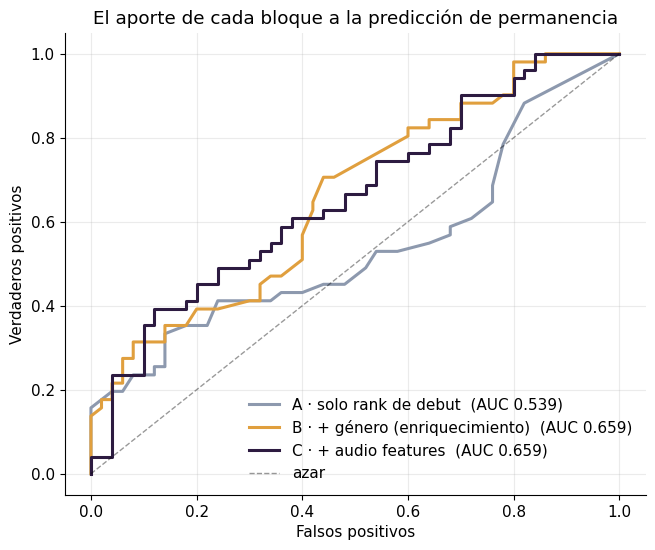

In [12]:
# --- Figura: curva ROC de los tres bloques
fig, ax = plt.subplots(figsize=(7.5, 6))
for (nombre, (m, c, Xt, yt, pr)), color in zip(guardados.items(), [GRIS, AMBAR, PLUM]):
    fpr, tpr, _ = roc_curve(yt, pr)
    ax.plot(fpr, tpr, lw=2.2, color=color,
            label=f"{nombre}  (AUC {roc_auc_score(yt, pr):.3f})")
ax.plot([0, 1], [0, 1], ls="--", lw=1, color="black", alpha=.4, label="azar")
ax.set_xlabel("Falsos positivos"); ax.set_ylabel("Verdaderos positivos")
ax.set_title("El aporte de cada bloque a la predicción de permanencia")
ax.legend(loc="lower right", frameon=False)
fig.savefig("m1_roc.png", dpi=150, bbox_inches="tight")
plt.show()


> **Cómo leer el ΔAUC.** Si el bloque B sube el AUC de forma apreciable, el género
> aporta y el enriquecimiento está haciendo trabajo real en el modelo. Si el bloque C
> casi no suma, confirma lo que el EDA de PC1 ya insinuaba: **el sonido importa poco
> frente al empuje del lanzamiento y al género.**
>
> Para el cliente eso significa que la decisión de fichaje pasa más por *qué tipo de
> repertorio* y *con cuánto respaldo se lanza* que por el perfil sonoro de la canción.


---
# 5. Modelo 2 — Serie de tiempo

**H4: ¿la rotación del Top 50 Perú tiene estacionalidad aprovechable?**

Serie: proporción del Top 50 que es nueva respecto al día anterior. Es la serie
declarada en la ficha del caso.

**Los 22 días faltantes del panel** (detectados en PC1) se reindexan e interpolan
únicamente para que STL pueda correr, porque exige frecuencia regular. Esas fechas se
excluyen de la evaluación del forecast, así que las métricas de error no se calculan sobre
datos inventados. Los promedios por día y por mes también se calculan solo con días reales.


In [13]:
por_dia = pe.groupby("snapshot_date")["spotify_id"].apply(set).sort_index()
fechas_chart = por_dia.index.to_list()

filas = []
for ant, act in zip(fechas_chart[:-1], fechas_chart[1:]):
    prev, curr = por_dia[ant], por_dia[act]
    filas.append({"fecha": act, "gap_dias": (act - ant).days, "n_chart": len(curr),
                  "entradas": len(curr - prev),
                  "rotacion": len(curr - prev) / len(curr) if curr else np.nan})
serie = pd.DataFrame(filas)
serie["rotacion_ma7"] = serie["rotacion"].rolling(7, min_periods=3).mean()

banner("SERIE DE ROTACIÓN DIARIA")
print(f"  días de la serie:  {len(serie)}")
print(f"  rotación media:    {serie['rotacion'].mean():.1%} del Top 50 por día")
print(f"  mínimo / máximo:   {serie['rotacion'].min():.1%} / {serie['rotacion'].max():.1%}")
print(f"  huecos del panel:  {(serie['gap_dias'] > 1).sum()}")



SERIE DE ROTACIÓN DIARIA
  días de la serie:  580
  rotación media:    3.6% del Top 50 por día
  mínimo / máximo:   0.0% / 38.0%
  huecos del panel:  6


In [14]:
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing

HOLDOUT = 30

s = serie.set_index("fecha")["rotacion"].astype(float)
idx = pd.date_range(s.index.min(), s.index.max(), freq="D")
faltantes = idx.difference(s.index)
s_full = s.reindex(idx).interpolate(limit_direction="both")

stl = STL(s_full, period=7, robust=True).fit()
f_estacional = max(0.0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
f_tendencia = max(0.0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())

train, test = s_full[:-HOLDOUT], s_full[-HOLDOUT:]
modelo_ts = ExponentialSmoothing(train, trend="add", seasonal="add",
                                 seasonal_periods=7).fit()
pred = modelo_ts.forecast(HOLDOUT)

real = ~test.index.isin(faltantes)        # no evaluar sobre días interpolados
# Métricas de error. El MAPE de PC1 no aplica: el holdout tiene días con rotación 0 y
# dividir entre 0 da infinito. Se reporta RMSE/MAE y se compara contra un pronóstico ingenuo.
yt, yp = test[real], pred[real]
rmse = float(np.sqrt(np.mean((yt - yp) ** 2)))
mae = float(np.mean(np.abs(yt - yp)))
rmse_media = float(np.sqrt(np.mean((yt - train.mean()) ** 2)))          # ingenuo: media histórica
rmse_ult30 = float(np.sqrt(np.mean((yt - train[-HOLDOUT:].mean()) ** 2)))  # ingenuo: media del último mes
dias_cero = int((yt == 0).sum())

resumen_ts = pd.DataFrame([
    ("Días del panel con dato real", len(s)),
    ("Días faltantes (interpolados solo para STL)", len(faltantes)),
    ("Rotación media", f"{s.mean():.1%}"),
    ("Fuerza de la estacionalidad semanal", round(f_estacional, 3)),
    ("Fuerza de la tendencia", round(f_tendencia, 3)),
    (f"RMSE del modelo en holdout de {HOLDOUT} días", round(rmse, 4)),
    ("MAE del modelo", round(mae, 4)),
    ("RMSE si se predice la media histórica", round(rmse_media, 4)),
    ("RMSE si se predice la media del último mes", round(rmse_ult30, 4)),
    ("Días con rotación 0 en el holdout", dias_cero),
    ("Criterio declarado en PC1", "MAPE <= 15% (no aplicable: hay días con 0)"),
    ("Veredicto", "MEJORA AL PRONÓSTICO INGENUO" if rmse < rmse_media else "NO MEJORA AL PRONÓSTICO INGENUO"),
], columns=["concepto", "valor"])

banner("MODELO DE SERIE DE TIEMPO")
print(resumen_ts.to_string(index=False))
print()
print(f"Lectura: el modelo se equivoca en promedio {rmse*100:.1f} puntos porcentuales de rotación;")
print(f"predecir la media histórica se equivocaría {rmse_media*100:.1f}. La mejora frente a la media")
print(f"del último mes ({rmse_ult30*100:.1f}) es mínima: sirve para anticipar picos, no para planificar día a día.")



MODELO DE SERIE DE TIEMPO
                                   concepto                                      valor
               Días del panel con dato real                                        580
Días faltantes (interpolados solo para STL)                                         22
                             Rotación media                                       3.6%
        Fuerza de la estacionalidad semanal                                      0.156
                     Fuerza de la tendencia                                      0.209
      RMSE del modelo en holdout de 30 días                                     0.0341
                             MAE del modelo                                      0.027
      RMSE si se predice la media histórica                                     0.0432
 RMSE si se predice la media del último mes                                     0.0348
          Días con rotación 0 en el holdout                                          1
                

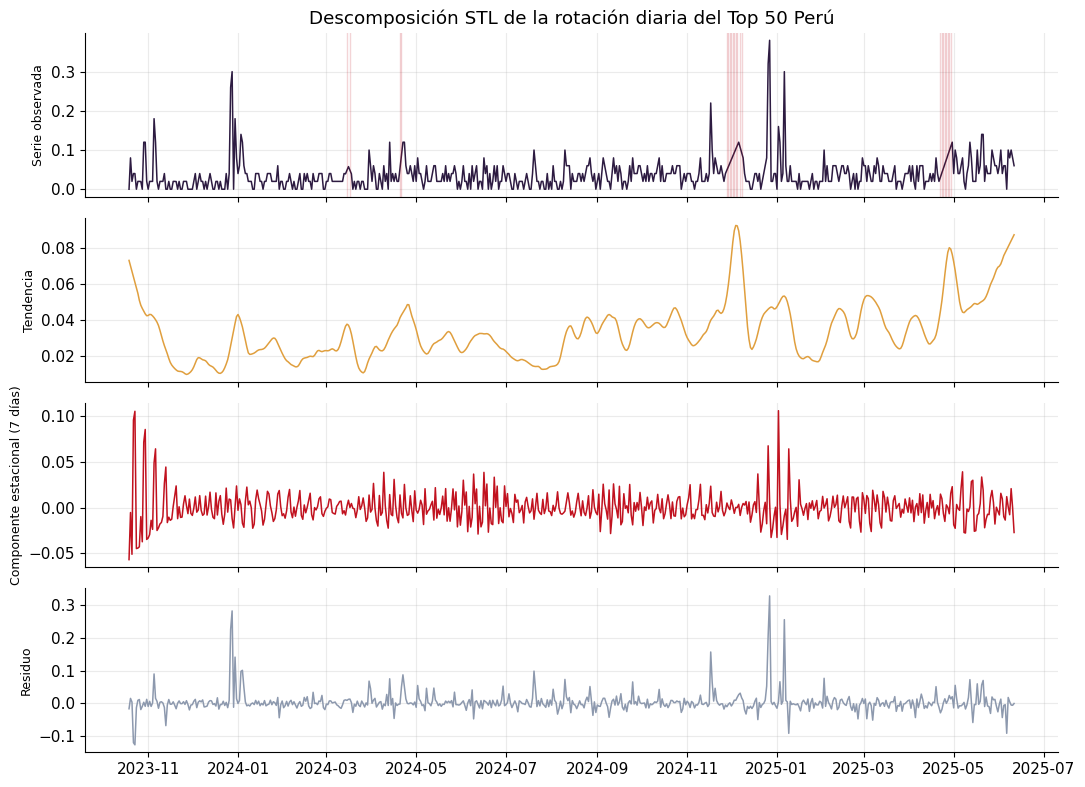

In [15]:
# --- Figura: descomposición STL
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, (datos, titulo, color) in zip(axes, [
        (s_full, "Serie observada", PLUM),
        (stl.trend, "Tendencia", AMBAR),
        (stl.seasonal, "Componente estacional (7 días)", CARMIN),
        (stl.resid, "Residuo", GRIS)]):
    ax.plot(datos.index, datos.values, lw=1.1, color=color)
    ax.set_ylabel(titulo, fontsize=9)
for f in faltantes:
    axes[0].axvline(f, color=CARMIN, alpha=.18, lw=1)
axes[0].set_title("Descomposición STL de la rotación diaria del Top 50 Perú")
fig.tight_layout()
fig.savefig("m2_stl.png", dpi=150, bbox_inches="tight")
plt.show()


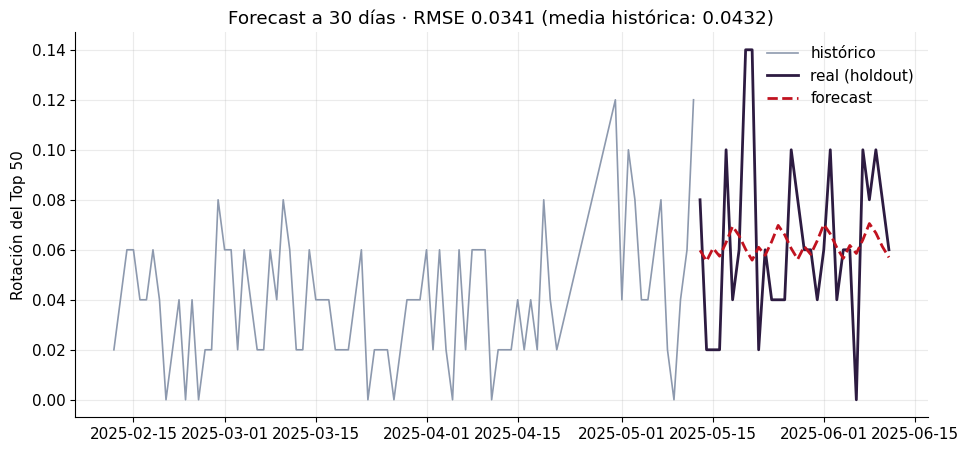

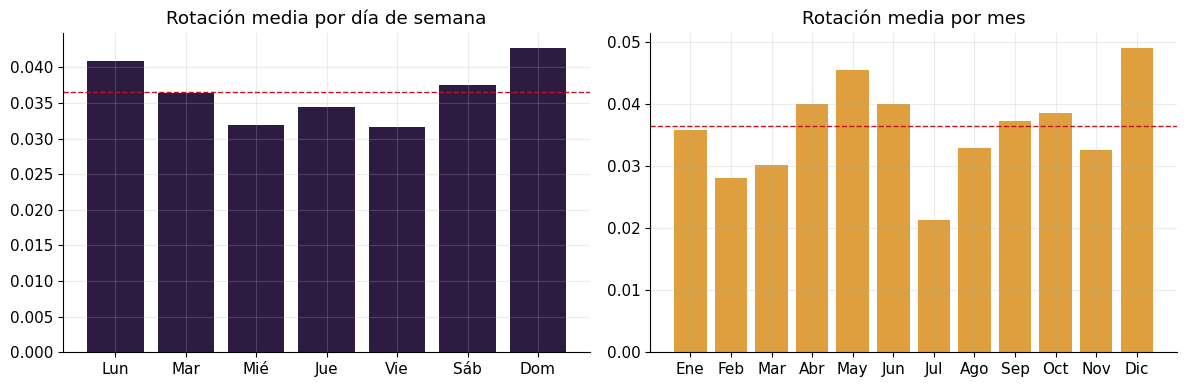


ESTACIONALIDAD
Por día de semana (la línea roja es la media global):
Lun    4.1
Mar    3.6
Mié    3.2
Jue    3.4
Vie    3.2
Sáb    3.8
Dom    4.3

Por mes:
Ene    3.6
Feb    2.8
Mar    3.0
Abr    4.0
May    4.5
Jun    4.0
Jul    2.1
Ago    3.3
Sep    3.7
Oct    3.9
Nov    3.3
Dic    4.9


In [16]:
# --- Figura: forecast contra holdout
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(train.index[-90:], train.values[-90:], lw=1.2, color=GRIS, label="histórico")
ax.plot(test.index, test.values, lw=2, color=PLUM, label="real (holdout)")
ax.plot(pred.index, pred.values, lw=2, ls="--", color=CARMIN, label="forecast")
ax.set_ylabel("Rotación del Top 50")
ax.set_title(f"Forecast a {HOLDOUT} días · RMSE {rmse:.4f} (media histórica: {rmse_media:.4f})")
ax.legend(frameon=False)
fig.savefig("m2_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

# --- estacionalidad por día de semana y por mes (solo días reales, sin interpolados)
dow = s.groupby(s.index.dayofweek).mean()
dow.index = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
mes = s.groupby(s.index.month).mean()
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
mes.index = [MESES[i - 1] for i in mes.index]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(dow.index, dow.values, color=PLUM)
axes[0].axhline(s.mean(), color=CARMIN, ls="--", lw=1)
axes[0].set_title("Rotación media por día de semana")
axes[1].bar(mes.index, mes.values, color=AMBAR)
axes[1].axhline(s.mean(), color=CARMIN, ls="--", lw=1)
axes[1].set_title("Rotación media por mes")
fig.tight_layout()
fig.savefig("m2_estacionalidad.png", dpi=150, bbox_inches="tight")
plt.show()

banner("ESTACIONALIDAD")
print("Por día de semana (la línea roja es la media global):")
print((dow * 100).round(1).to_string())
print()
print("Por mes:")
print((mes * 100).round(1).to_string())


> **Cómo traducirlo al cliente.** La rotación es la velocidad a la que el chart se
> renueva. Si es alta, la ventana de exposición de una canción es corta y el calendario
> de lanzamiento importa.
>
> Mira la figura de estacionalidad: los meses por debajo de la línea roja son los de
> **menor rotación**, es decir donde una canción que entra tiene más probabilidad de
> quedarse. Ese es el mes que se recomienda para lanzar.


---
# 6. Modelo 3 — Clustering

**H1: ¿existe un perfil sonoro que caracterice al repertorio peruano?**

K-means sobre las nueve audio features. Se estandariza primero, porque `loudness` va en
decibelios y `tempo` en BPM mientras el resto está acotado entre 0 y 1.

El enunciado pide **nombrar cada segmento con criterio de negocio** y **responder cuál
representa la mayor oportunidad**. Ambas cosas están abajo.


In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

dc = tab.dropna(subset=AUDIO).copy()
Xc = StandardScaler().fit_transform(dc[AUDIO])

sel = []
for k in range(3, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Xc)
    sel.append({"k": k, "silueta": round(silhouette_score(Xc, km.labels_), 3),
                "inercia": round(km.inertia_, 1)})
seleccion = pd.DataFrame(sel)
K = int(seleccion.loc[seleccion["silueta"].idxmax(), "k"])

km = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(Xc)
dc["cluster"] = km.labels_

banner("SELECCIÓN DE k")
print(seleccion.to_string(index=False))
print(f"\n  k elegido por silueta: {K}")
print(f"  Criterio declarado en PC1: 3 a 6 clústeres, silueta >= 0.25, n >= 20 cada uno")
sil = seleccion.loc[seleccion['k'] == K, 'silueta'].iloc[0]
print(f"  Silueta obtenida: {sil}  ->  {'CUMPLE' if sil >= 0.25 else 'NO CUMPLE'}")



SELECCIÓN DE k
 k  silueta  inercia
 3    0.211   2759.2
 4    0.200   2459.8
 5    0.192   2245.2
 6    0.194   2057.3

  k elegido por silueta: 3
  Criterio declarado en PC1: 3 a 6 clústeres, silueta >= 0.25, n >= 20 cada uno
  Silueta obtenida: 0.211  ->  NO CUMPLE


In [18]:
perfil = dc.groupby("cluster")[AUDIO].mean().round(3)
perfil["n"] = dc["cluster"].value_counts().sort_index()
perfil["dias_medios"] = dc.groupby("cluster")["dias_en_chart"].mean().round(1)
perfil["%_sobrevive"] = (dc.groupby("cluster")["sobrevive"].mean() * 100).round(1)
perfil["%_traccion_local"] = (dc.groupby("cluster")["traccion_local"].mean() * 100).round(1)

# --- nombre de negocio: las dos features que más se desvían de la media
centro, sd = perfil[AUDIO].mean(), perfil[AUDIO].std().replace(0, 1)
z = (perfil[AUDIO] - centro) / sd
ETIQ = {"danceability": ("más bailable", "menos bailable"),
        "energy": ("más enérgico", "más suave"),
        "loudness": ("más fuerte", "más tenue"),
        "speechiness": ("más hablado", "más melódico"),
        "acousticness": ("más acústico", "más producido"),
        "instrumentalness": ("más instrumental", "más vocal"),
        "liveness": ("más en vivo", "más de estudio"),
        "valence": ("más alegre", "más melancólico"),
        "tempo": ("más rápido", "más lento")}
desc = {}
for c in perfil.index:
    top2 = z.loc[c].abs().sort_values(ascending=False).head(2)
    desc[c] = " y ".join(ETIQ[f][0] if z.loc[c, f] > 0 else ETIQ[f][1] for f in top2.index)
perfil["descripcion"] = pd.Series(desc)

banner("PERFIL DE CADA CLÚSTER")
print(perfil[["n", "dias_medios", "%_sobrevive", "%_traccion_local", "descripcion"]].to_string())



PERFIL DE CADA CLÚSTER
           n  dias_medios  %_sobrevive  %_traccion_local                   descripcion
cluster                                                                               
0         13         94.9         84.6               0.0  más instrumental y más tenue
1        132         47.8         35.6              15.2        más rápido y más vocal
2        296         72.7         47.0              31.1  más producido y más melódico


In [19]:
# --- ¿los clústeres separan géneros, o el sonido no distingue repertorio?
comp = (pd.crosstab(dc["cluster"], dc["genero"], normalize="index") * 100).round(1)
banner("COMPOSICIÓN DE GÉNERO POR CLÚSTER (%)")
print(comp.to_string())
print()
print("Si todas las filas se parecen, los clústeres NO separan géneros:")
print("el sonido no distingue el tipo de repertorio, que es lo que dijo H1 en PC1.")



COMPOSICIÓN DE GÉNERO POR CLÚSTER (%)
genero   cumbia  hip_hop  k-pop  pop_internacional  pop_latino  regional_mexicano  rock  salsa  urbano_latino
cluster                                                                                                      
0           0.0      0.0    0.0                0.0         0.0                0.0   0.0    0.0          100.0
1           2.0      1.0    9.2               13.3         4.1                4.1   0.0    0.0           66.3
2          10.7      3.1   10.7                6.7         0.9                3.6   0.4    1.3           62.7

Si todas las filas se parecen, los clústeres NO separan géneros:
el sonido no distingue el tipo de repertorio, que es lo que dijo H1 en PC1.


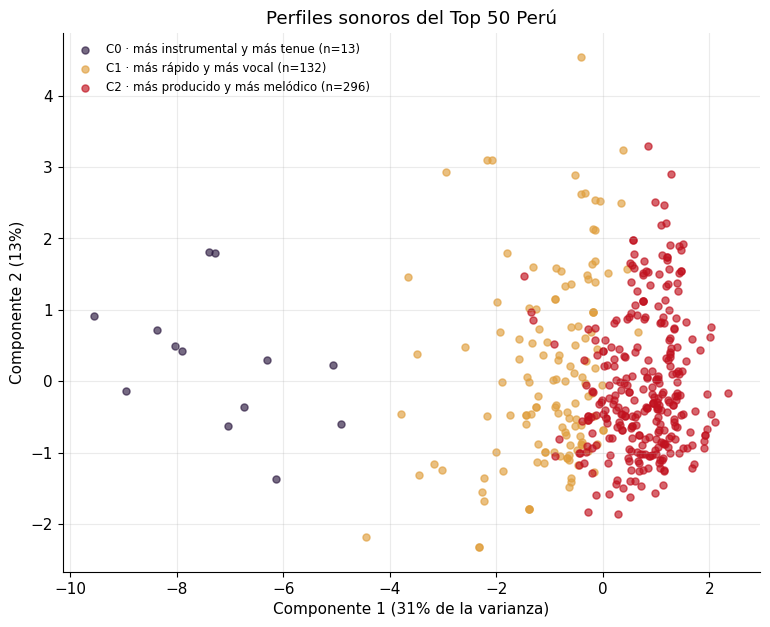

In [20]:
# --- Figura: clústeres proyectados en 2D
pca = PCA(n_components=2, random_state=SEMILLA)
XY = pca.fit_transform(Xc)
fig, ax = plt.subplots(figsize=(9, 7))
colores = [PLUM, AMBAR, CARMIN, GRIS, "#2C6E49", "#4A3465"]
for c in sorted(dc["cluster"].unique()):
    m = dc["cluster"] == c
    ax.scatter(XY[m.values, 0], XY[m.values, 1], s=26, alpha=.65,
               color=colores[c % len(colores)],
               label=f"C{c} · {perfil.loc[c, 'descripcion']} (n={perfil.loc[c, 'n']})")
ax.set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)")
ax.set_ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Perfiles sonoros del Top 50 Perú")
ax.legend(fontsize=8.5, frameon=False)
fig.savefig("m3_clusters.png", dpi=150, bbox_inches="tight")
plt.show()


In [21]:
# --- ¿Qué segmento es la mayor oportunidad? (lo pide el enunciado, textual)
opor = perfil[["n", "dias_medios", "%_sobrevive", "%_traccion_local", "descripcion"]].copy()
opor["score_oportunidad"] = (opor["%_traccion_local"] * opor["dias_medios"] / 100).round(1)
opor = opor.sort_values("score_oportunidad", ascending=False)

banner("¿QUÉ SEGMENTO ES LA MAYOR OPORTUNIDAD?")
print("score = % de tracción local × días medios en chart / 100")
print("Combina 'Perú lo sostiene solo' con 'dura cuando entra'.")
print()
print(opor.to_string())
print()
ganador = opor.index[0]
print(f"MAYOR OPORTUNIDAD: clúster {ganador} — {opor.loc[ganador, 'descripcion']}")
print(f"  {opor.loc[ganador, 'n']} canciones · {opor.loc[ganador, '%_traccion_local']}% de tracción local")
print(f"  permanencia media de {opor.loc[ganador, 'dias_medios']} días")



¿QUÉ SEGMENTO ES LA MAYOR OPORTUNIDAD?
score = % de tracción local × días medios en chart / 100
Combina 'Perú lo sostiene solo' con 'dura cuando entra'.

           n  dias_medios  %_sobrevive  %_traccion_local                   descripcion  score_oportunidad
cluster                                                                                                  
2        296         72.7         47.0              31.1  más producido y más melódico               22.6
1        132         47.8         35.6              15.2        más rápido y más vocal                7.3
0         13         94.9         84.6               0.0  más instrumental y más tenue                0.0

MAYOR OPORTUNIDAD: clúster 2 — más producido y más melódico
  296 canciones · 31.1% de tracción local
  permanencia media de 72.7 días


---
# 7. Pregunta huérfana

> **¿Qué géneros concentran escucha declarada del oyente peruano muy por encima de su
> presencia en el Top 50 Perú, y por qué canal de descubrimiento llega esa música?**

Ahora sí se puede responder: el lado de la encuesta ya estaba desde PC1, y el lado del
chart necesitaba el etiquetado de géneros de la sección 2.

El cruce es **a nivel de género**, no de canción: un respondente declara géneros, no
canciones, así que no existe correspondencia individuo-canción y no se pretende que la haya.


In [22]:
MAPA_ENCUESTA = {
    "Reggaetón y urbano latino": "urbano_latino",
    "Pop latino": "pop_latino",
    "Cumbia y tecnocumbia": "cumbia",
    "Salsa": "salsa",
    "Trap y hip-hop en español": "hip_hop",
    "Rock y pop en español": "rock",
    "Música criolla y vals peruano": "criolla",
    "Corridos tumbados y regional mexicano": "regional_mexicano",
    "Pop y rock en inglés": "pop_internacional",
    "K-pop": "k-pop",
}

# --- lado encuesta: pasar a formato largo si viene ancho
TEXTO_CONTROL = "Para verificar que estás leyendo"
FRECUENCIA = {"Nunca": 1, "Una vez": 2, "Algunos días": 3,
              "Casi todos los días": 4, "Todos los días": 5}

cols_grid = [c for c in encuesta.columns
             if c.strip().startswith("5.") and "[" in c and TEXTO_CONTROL not in c]

if cols_grid:                      # formato ancho (export de Forms limpio)
    largo_enc = (encuesta[cols_grid].reset_index().rename(columns={"index": "_id"})
                 .melt(id_vars="_id", var_name="columna", value_name="respuesta"))
    largo_enc["genero"] = largo_enc["columna"].str.extract(r"\[(.+)\]")[0].str.strip()
    largo_enc["frecuencia"] = largo_enc["respuesta"].map(FRECUENCIA)
else:                              # ya viene largo
    largo_enc = encuesta.rename(columns={c: c.lower() for c in encuesta.columns}).copy()

largo_enc = largo_enc.dropna(subset=["genero", "frecuencia"])
largo_enc["genero_cod"] = largo_enc["genero"].map(MAPA_ENCUESTA)
n_resp = largo_enc["_id"].nunique()
print(f"respondentes: {n_resp}  ·  filas género×persona: {len(largo_enc):,}")


respondentes: 67  ·  filas género×persona: 670


In [23]:
# --- lado encuesta: alcance semanal por género
alcance = (largo_enc.assign(escucho=(largo_enc["frecuencia"] >= 2).astype(int))
           .groupby("genero_cod")["escucho"].mean()
           .rename("alcance_encuesta").reset_index())
alcance["share_declarado"] = alcance["alcance_encuesta"] / alcance["alcance_encuesta"].sum()

# --- lado chart: share de días-chart por género
chart_gen = pe.merge(generos[["spotify_id", "genero"]], on="spotify_id", how="left")
share_chart = (chart_gen["genero"].value_counts(normalize=True)
               .rename("share_chart").reset_index())
share_chart.columns = ["genero_cod", "share_chart"]

brecha = alcance.merge(share_chart, on="genero_cod", how="outer").fillna(0)
brecha["alcance_%"] = (brecha["alcance_encuesta"] * 100).round(1)
brecha["share_declarado_%"] = (brecha["share_declarado"] * 100).round(1)
brecha["share_chart_%"] = (brecha["share_chart"] * 100).round(1)
brecha["brecha_pp"] = (brecha["share_declarado_%"] - brecha["share_chart_%"]).round(1)
brecha["razon"] = np.where(brecha["share_chart"] > 0,
                           (brecha["share_declarado"] / brecha["share_chart"]).round(2),
                           np.inf)
brecha = brecha.sort_values("brecha_pp", ascending=False)

banner(f"BRECHA: ESCUCHA DECLARADA vs PRESENCIA EN EL CHART (n = {n_resp})")
print(brecha[["genero_cod", "alcance_%", "share_declarado_%", "share_chart_%",
              "brecha_pp", "razon"]].to_string(index=False))
print()
print("Criterio declarado en PC1: hallazgo si algún género supera razón de 2x")
sup = brecha[(brecha["razon"] > 2) & (brecha["share_chart"] > 0)]
print(f"Géneros con razón > 2x: {len(sup)}  ->  {'HAY HALLAZGO' if len(sup) else 'SIN BRECHA RELEVANTE'}")
if len(sup):
    print(sup[["genero_cod", "alcance_%", "share_chart_%", "razon"]].to_string(index=False))



BRECHA: ESCUCHA DECLARADA vs PRESENCIA EN EL CHART (n = 67)
       genero_cod  alcance_%  share_declarado_%  share_chart_%  brecha_pp   razon
             rock       82.1               13.2            0.0       13.2 3457.07
       pop_latino       85.1               13.7            0.8       12.9   17.06
pop_internacional       94.0               15.1            4.8       10.3    3.18
            salsa       61.2                9.9            0.1        9.8  143.17
          hip_hop       59.7                9.6            2.1        7.5    4.64
          criolla       38.8                6.2            0.0        6.2     inf
            k-pop       35.8                5.8            3.9        1.9    1.47
           cumbia       49.3                7.9            7.4        0.5    1.07
regional_mexicano       32.8                5.3            6.2       -0.9    0.85
    urbano_latino       82.1               13.2           74.7      -61.5    0.18

Criterio declarado en PC1: hallazgo 

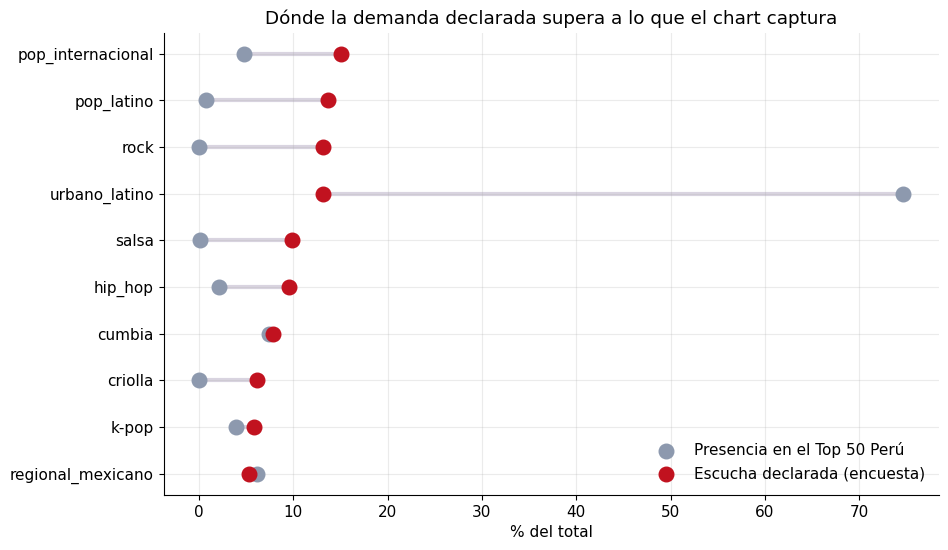

In [24]:
# --- Figura: la brecha, género por género
b = brecha.sort_values("share_declarado_%")
yy = np.arange(len(b))
fig, ax = plt.subplots(figsize=(10, 6))
ax.hlines(yy, b["share_chart_%"], b["share_declarado_%"], color="#D9D4E0", lw=3, zorder=1)
ax.scatter(b["share_chart_%"], yy, s=110, color=GRIS, zorder=2, label="Presencia en el Top 50 Perú")
ax.scatter(b["share_declarado_%"], yy, s=110, color=CARMIN, zorder=2, label="Escucha declarada (encuesta)")
ax.set_yticks(yy); ax.set_yticklabels(b["genero_cod"])
ax.set_xlabel("% del total")
ax.set_title("Dónde la demanda declarada supera a lo que el chart captura")
ax.legend(frameon=False, loc="lower right")
fig.savefig("m4_brecha.png", dpi=150, bbox_inches="tight")
plt.show()


In [25]:
# --- segunda mitad de la huérfana: el canal de descubrimiento
if "canal_descubrimiento" in encuesta.columns:
    canal = encuesta["canal_descubrimiento"].value_counts(normalize=True).mul(100).round(1)
    banner("POR QUÉ CANAL LLEGA ESA MÚSICA")
    print(canal.to_string())
    pasivo = canal[canal.index.str.contains("algorítmica|TikTok|editorial", case=False, na=False)].sum()
    print()
    print(f"Descubrimiento pasivo (algoritmo + redes + editorial): {pasivo:.1f}%")
    print("Para el cliente: la inversión rinde más en conseguir posición en playlists")
    print("que en campañas dirigidas al artista.")
else:
    print("La columna canal_descubrimiento no está en el CSV; revisar el export de PC1.")



POR QUÉ CANAL LLEGA ESA MÚSICA
canal_descubrimiento
Playlist algorítmica (Descubrimiento semanal, Radio, Mix)    38.8
TikTok, Reels o Shorts                                       31.3
La busqué yo a propósito                                     11.9
Me la recomendó una persona                                  10.4
No recuerdo                                                   6.0
Playlist editorial de la plataforma                           1.5

Descubrimiento pasivo (algoritmo + redes + editorial): 71.6%
Para el cliente: la inversión rinde más en conseguir posición en playlists
que en campañas dirigidas al artista.


---
# 8. Recomendación — la lista de fichaje

**Este es el criterio 3 de la rúbrica PC2 y vale 5 puntos.** El cliente tiene que poder
tomar una decisión concreta con esto.

**Advertencia de coherencia, que es un tope de la rúbrica.** H1 se refutó en PC1: el
sonido no distingue al repertorio peruano. Por lo tanto **la recomendación NO puede
salir del clustering de audio features.** Sale del género y de la tracción local, que es
donde sí hay señal. El clustering describe el mercado; no decide a quién fichar.


In [26]:
# --- Candidatos: artistas con tracción local sostenida
locales = tab[tab["traccion_local"] == 1].copy()

art = (explotar(locales[["spotify_id", "artistas", "dias_en_chart",
                         "indice_localidad", "genero", "mejor_rank"]], "artistas")
       .groupby("artista_norm")
       .agg(canciones=("spotify_id", "nunique"),
            dias_total=("dias_en_chart", "sum"),
            dias_max=("dias_en_chart", "max"),
            indice_medio=("indice_localidad", "mean"),
            mejor_rank=("mejor_rank", "min"),
            genero=("genero", lambda s: s.mode().iloc[0] if len(s.mode()) else None))
       .reset_index())

# nombre legible: la grafía más frecuente en el panel (conserva tildes)
largo_loc = locales[["spotify_id", "artistas"]].copy()
largo_loc["nombre"] = largo_loc["artistas"].fillna("").astype(str).str.split(r";|,|&|/", regex=True)
largo_loc = largo_loc.explode("nombre")
largo_loc["nombre"] = largo_loc["nombre"].str.strip()
largo_loc["artista_norm"] = largo_loc["nombre"].map(norm)
grafia = (largo_loc[largo_loc["artista_norm"] != ""]
          .groupby("artista_norm")["nombre"].agg(lambda x: x.mode().iloc[0]))
art["artista"] = art["artista_norm"].map(grafia).fillna(art["artista_norm"].str.title())

art = art[art["canciones"] >= 1].sort_values(
    ["canciones", "dias_total"], ascending=False)

banner("CANDIDATOS A FICHAJE — artistas con tracción exclusivamente peruana")
print(f"Total de artistas con al menos una canción de tracción local: {len(art)}")
print()
print(art.head(25)[["artista", "genero", "canciones", "dias_total",
                    "dias_max", "indice_medio", "mejor_rank"]]
      .round(1).to_string(index=False))
art.to_csv("candidatos_fichaje.csv", index=False)

# --- La lista corta: candidatos de cumbia ordenados por índice de localidad
corta = (art[art["genero"] == "cumbia"]
         .sort_values("indice_medio", ascending=False))
banner("LISTA CORTA — cumbia con tracción local, por índice de localidad")
print(corta.head(8)[["artista", "canciones", "dias_total", "indice_medio", "mejor_rank"]]
      .round(1).to_string(index=False))



CANDIDATOS A FICHAJE — artistas con tracción exclusivamente peruana
Total de artistas con al menos una canción de tracción local: 136

            artista            genero  canciones  dias_total  dias_max  indice_medio  mejor_rank
          Bad Bunny     urbano_latino          8         599       380          13.8           8
              Beéle     urbano_latino          7         380       106          11.1           8
     Rauw Alejandro     urbano_latino          6         689       201          30.9          11
               Feid     urbano_latino          5        1483       463           3.4           3
  La Única Tropical            cumbia          4         973       354         243.2           1
          Jung Kook             k-pop          4         327       179          39.0           2
Pedro Suárez-Vértiz              None          4          63        29          15.8           3
            Piso 21     urbano_latino          3         285       112          26.3    

In [27]:
# --- Resumen por género: dónde conviene concentrar la inversión
res_gen = (tab.dropna(subset=["genero"]).groupby("genero")
           .agg(canciones=("spotify_id", "count"),
                dias_medios=("dias_en_chart", "mean"),
                pct_sobrevive=("sobrevive", "mean"),
                pct_traccion_local=("traccion_local", "mean"),
                rank_debut_medio=("rank_debut", "mean"))
           .round(2).reset_index())
res_gen["pct_sobrevive"] = (res_gen["pct_sobrevive"] * 100).round(1)
res_gen["pct_traccion_local"] = (res_gen["pct_traccion_local"] * 100).round(1)

# brecha de la encuesta, para unir las dos señales
res_gen = res_gen.merge(brecha[["genero_cod", "alcance_%", "share_chart_%", "razon"]],
                        left_on="genero", right_on="genero_cod", how="left").drop(columns="genero_cod")
res_gen = res_gen.sort_values("pct_traccion_local", ascending=False)

banner("RESUMEN POR GÉNERO — la base de la recomendación")
print(res_gen.to_string(index=False))
res_gen.to_csv("resumen_por_genero.csv", index=False)



RESUMEN POR GÉNERO — la base de la recomendación
           genero  canciones  dias_medios  pct_sobrevive  pct_traccion_local  rank_debut_medio  alcance_%  share_chart_%   razon
       pop_latino          6        35.00           33.0                50.0             40.83       85.1            0.8   17.06
           cumbia         26        74.50           42.0                42.0             40.00       49.3            7.4    1.07
            k-pop         33        31.03           18.0                33.0             28.36       35.8            3.9    1.47
            salsa          3         6.00            0.0                33.0             44.33       61.2            0.1  143.17
          hip_hop          8        67.75           50.0                25.0             40.88       59.7            2.1    4.64
pop_internacional         28        44.54           36.0                25.0             34.79       94.0            4.8    3.18
    urbano_latino        219        89.24      

### 8.1 Cómo construir la recomendación con estas dos tablas

El argumento tiene que encadenar las tres evidencias, en este orden:

1. **La encuesta dice dónde mirar** — los géneros con `razon` alta tienen demanda
   declarada que el chart no captura.
2. **El chart dice a quién** — dentro de esos géneros, la tabla de candidatos lista los
   artistas con tracción local sostenida y cuántos días duran.
3. **El modelo dice qué esperar** — la regresión da la probabilidad de que ese
   repertorio se consolide, y la serie de tiempo dice cuándo lanzarlo.

Escribe la recomendación final en la celda de abajo, **con los números que acabas de
obtener**, no con los de PC1.


## 8.2 Recomendación final

**Decisión para el cliente: entrar a Perú fichando cumbia con tracción local y concentrar el presupuesto en el lanzamiento.**

1. **Género prioritario: cumbia.** El 42% de sus canciones tiene tracción solo en Perú, frente a 21% del urbano latino (sección 8, resumen por género). Dura en promedio 74,5 días en el chart. Es el repertorio que el mercado regional no trae.
2. **Artistas candidatos** (lista corta de la celda anterior):
   - **La Única Tropical**: 4 canciones, 973 días acumulados, índice de localidad 243, llegó al #1.
   - **Eddy Herrera**: 124 días, índice 124, mejor puesto #8.
   - **Grupo 5**: 2 canciones, 141 días, índice 70,5.
   - **Kate Candela** y **Son del Duke**: 78 días cada uno, índice 78.
3. **Qué esperar:** el modelo de permanencia tiene AUC 0,659. El género es lo que más aporta (+0,12 de AUC sobre el modelo con solo el debut); las audio features no suman (+0,00). El debut pesa: cada desviación estándar más abajo en el puesto de debut reduce ~43% las probabilidades de durar 28 días (odds ratio 0,567). **El presupuesto va a que la canción debute alto.**
4. **Cuándo lanzar:** evitar diciembre, que tiene la rotación más alta (4,9% diario contra 3,6% de media). Julio es el mes de menor rotación (2,1%), así que una canción que entra en julio compite con menos estrenos. La estacionalidad es débil (fuerza 0,16): es una preferencia de calendario, no una regla.
5. **Dónde promocionar:** el 71,6% de los encuestados descubre música sin buscarla: playlists algorítmicas (38,8%) y TikTok, Reels o Shorts (31,3%). La playlist editorial pesa 1,5%.
6. **Validar antes de invertir:** pop latino (lo escucha el 85%, pesa 0,8% del chart) y salsa (61%, 0,1%) muestran demanda que el chart no captura (pregunta huérfana, sección 7). Antes de fichar ahí, conviene validarlo con datos de streams por artista.

**Lo que no se recomienda:** fichar por perfil sonoro. El clustering no separa al repertorio peruano (silueta 0,211 < 0,25) y las audio features no mejoran la predicción. Recomendar por sonido contradiría los modelos.

**Límites:** la regresión no alcanza el AUC 0,70 fijado en PC1; el 23,8% de las canciones quedó sin género; la encuesta (n = 67) es por conveniencia y se lee como señal direccional.


---
# 9. Exports para el dashboard de Power BI

Cada archivo es una tabla plana, sin índices de varios niveles. En el proyecto de Power BI se cargan
desde una carpeta local con el parámetro `RutaDatos` (Inicio → Transformar datos → Editar parámetros).

1. Corre esta celda.
2. Descarga los CSV del panel de archivos de Colab (o con la celda siguiente, en un solo .zip).
3. Copia los CSV a la carpeta `datos` del proyecto de Power BI y actualiza.


In [28]:
# --- 1. Tabla principal: una fila por canción
export_canciones = tab[[
    "spotify_id", "nombre", "artistas", "genero", "fuente_genero",
    "dias_en_chart", "sobrevive", "mejor_rank", "rank_debut", "rank_medio",
    "indice_localidad", "traccion_local", "dias_region",
    "primer_dia", "ultimo_dia", *AUDIO]].copy()
export_canciones = export_canciones.merge(
    dc[["spotify_id", "cluster"]], on="spotify_id", how="left")
export_canciones["cluster_nombre"] = export_canciones["cluster"].map(perfil["descripcion"])
export_canciones.to_csv("lk_canciones.csv", index=False)

# --- 2. Serie diaria
export_serie = serie[["fecha", "rotacion", "rotacion_ma7", "entradas", "n_chart"]].copy()
export_serie["anio"] = export_serie["fecha"].dt.year
export_serie["mes"] = export_serie["fecha"].dt.month
export_serie["dia_semana"] = export_serie["fecha"].dt.day_name()
export_serie.to_csv("lk_serie_rotacion.csv", index=False)

# --- 3. Panel largo por país (para el mapa y la comparación regional)
export_panel = (panel.groupby(["spotify_id", "country"])
                .agg(dias=("snapshot_date", "nunique"),
                     mejor_rank=("daily_rank", "min"))
                .reset_index()
                .merge(generos[["spotify_id", "name", "artists", "genero"]],
                       on="spotify_id", how="left"))
export_panel.to_csv("lk_panel_paises.csv", index=False)

# --- 4. Resumen por género (une chart + encuesta)
res_gen.to_csv("lk_resumen_genero.csv", index=False)

# --- 5. Brecha de la pregunta huérfana
brecha.to_csv("lk_brecha_huerfana.csv", index=False)

# --- 6. Perfil de clústeres
perfil.reset_index().to_csv("lk_clusters.csv", index=False)

# --- 7. Métricas de los modelos (para la página Modelos del dashboard)
metricas_todas = pd.concat([
    metricas.assign(modelo="Regresión logística")[["modelo", "bloque", "AUC", "accuracy"]]
        .rename(columns={"bloque": "detalle", "AUC": "metrica_1", "accuracy": "metrica_2"}),
    pd.DataFrame([{"modelo": "Serie de tiempo", "detalle": f"holdout {HOLDOUT} días · RMSE modelo vs. media histórica",
                   "metrica_1": round(rmse, 4), "metrica_2": round(rmse_media, 4)}]),
    pd.DataFrame([{"modelo": "Clustering", "detalle": f"k = {K}",
                   "metrica_1": float(sil), "metrica_2": len(dc)}]),
])
metricas_todas.to_csv("lk_metricas_modelos.csv", index=False)

banner("ARCHIVOS GENERADOS")
import glob, os
for f in sorted(glob.glob("lk_*.csv")) + sorted(glob.glob("*.png")) + ["candidatos_fichaje.csv"]:
    if os.path.exists(f):
        print(f"  {f:<32} {os.path.getsize(f)/1024:>8.1f} KB")



ARCHIVOS GENERADOS
  lk_brecha_huerfana.csv                1.0 KB
  lk_canciones.csv                    100.5 KB
  lk_clusters.csv                       0.5 KB
  lk_metricas_modelos.csv               0.3 KB
  lk_panel_paises.csv                 139.6 KB
  lk_resumen_genero.csv                 0.5 KB
  lk_serie_rotacion.csv                31.9 KB
  m1_roc.png                           91.7 KB
  m2_estacionalidad.png                51.8 KB
  m2_forecast.png                     129.3 KB
  m2_stl.png                          277.4 KB
  m3_clusters.png                     133.5 KB
  m4_brecha.png                        69.9 KB
  candidatos_fichaje.csv                7.3 KB


In [29]:
# --- Descargar todos los exports en un solo .zip (solo en Colab)
import zipfile, glob
with zipfile.ZipFile("exports_pbi.zip", "w") as z:
    for f in glob.glob("lk_*.csv") + ["candidatos_fichaje.csv"] + glob.glob("*.png"):
        z.write(f)
try:
    from google.colab import files
    files.download("exports_pbi.zip")
except ImportError:
    print("exports_pbi.zip creado en la carpeta actual")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
from google.colab import files
import glob
for f in sorted(glob.glob("lk_*.csv")) + sorted(glob.glob("*.png")) + ["candidatos_fichaje.csv", "resumen_por_genero.csv"]:
    files.download(f)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (20 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# 10. Checklist contra la rúbrica PC2

**Topes de la rúbrica — estado:**

- [x] El enriquecimiento aparece en un modelo → el género (cruce con el catálogo) entra a la regresión y aporta +0,12 de AUC, sección 4
- [x] Tasa de cruce reportada → 76,2% de las canciones con género (38,5% lista manual + 37,6% catálogo), sección 2
- [x] Notebook reproducible de principio a fin → *Entorno de ejecución → Reiniciar y ejecutar todo*
- [x] Pregunta huérfana respondida → sección 7
- [x] La recomendación no contradice los modelos → sección 8.2, no se recomienda por perfil sonoro
- [x] Bitácora de IA y datos crudos → se entregan en la carpeta del proyecto

**Métricas contra los criterios declarados en PC1:**

| Modelo | Criterio declarado | Resultado | ¿Cumple? |
|---|---|---|---|
| Regresión | AUC ≥ 0,70 | AUC 0,659 (accuracy 0,604 vs. 0,509 de base) | No |
| Serie de tiempo | MAPE ≤ 15% | MAPE no aplicable (días con rotación 0). RMSE 0,034 vs. 0,043 de la media histórica | Se reemplazó la métrica |
| Clustering | silueta ≥ 0,25, 3–6 clústeres | k = 3, silueta 0,211 | No |
| Huérfana | razón > 2× en algún género | rock, salsa, pop latino, hip-hop y pop en inglés superan 2× | Sí |

Los criterios no alcanzados se reportan tal cual y se explican: la regresión sí demuestra que el
enriquecimiento agrega señal, y el clustering confirma que el perfil sonoro no sirve para decidir.
